In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from streamlit.dataframe_util import convert_anything_to_arrow_bytes

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [3]:
df=pd.read_csv('CAR DETAILS FROM CAR DEKHO.csv')

In [4]:
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [5]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [6]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


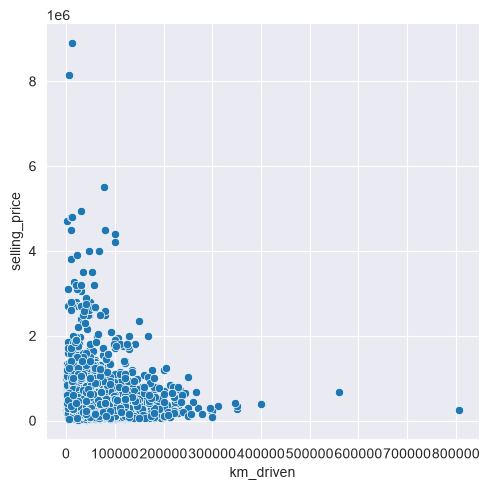

In [7]:
sns.relplot(data=df, x='km_driven', y='selling_price', kind='scatter')

In [8]:
print(f"YEARS: {df['year'].unique()}\nfuel:{df['fuel'].unique()}\nseller_type: {df['seller_type'].unique()} \ntransmission: {df['transmission'].unique()} \nowner: {df['owner'].unique()}")

YEARS: [2007 2012 2017 2014 2016 2015 2018 2019 2013 2011 2010 2009 2006 1996
 2005 2008 2004 1998 2003 2002 2020 2000 1999 2001 1995 1997 1992]
fuel:['Petrol' 'Diesel' 'CNG' 'LPG' 'Electric']
seller_type: ['Individual' 'Dealer' 'Trustmark Dealer'] 
transmission: ['Manual' 'Automatic'] 
owner: ['First Owner' 'Second Owner' 'Fourth & Above Owner' 'Third Owner'
 'Test Drive Car']


## FOR NOW PREDICTING PRICE ON BASIS OF KM DRIVEN ONLY

In [9]:
df2=df[['selling_price','km_driven']]

In [10]:
df2

,selling_price,km_driven
0,60000,70000
1,135000,50000
2,600000,100000
3,250000,46000
4,450000,141000
...,...,...
4335,409999,80000
4336,409999,80000
4337,110000,83000
4338,865000,90000


In [11]:
# we need TO FIND RELATION BETWEEN THESE 2 SELLING PRICE AND KM DRIVEN AND LL MAKE A SIMPLE LINER REGRESSION MODEL PREDICTING SELLING PRICE ON THE BASIS OF KM DRIVEN

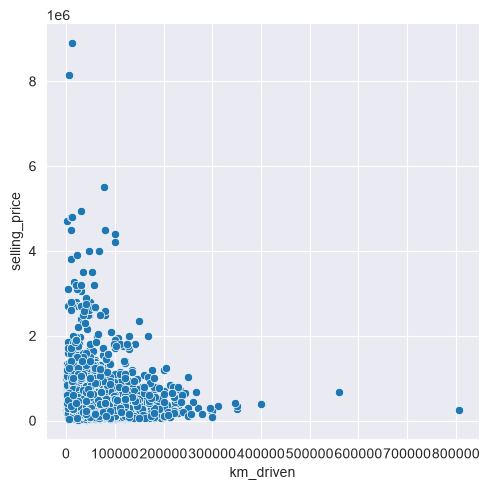

In [12]:
plot=sns.relplot(data=df2, x='km_driven', y='selling_price', kind='scatter')

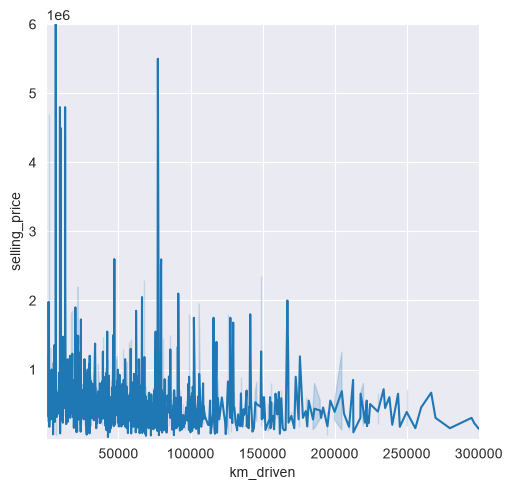

In [13]:
plot=sns.relplot(data=df2, x='km_driven', y='selling_price', kind='line')
plot.set(xlim=(10,300000),ylim=(1,6000000))
plt.show()

In [14]:
df.shape

(4340, 8)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


<Axes: xlabel='km_driven', ylabel='selling_price'>

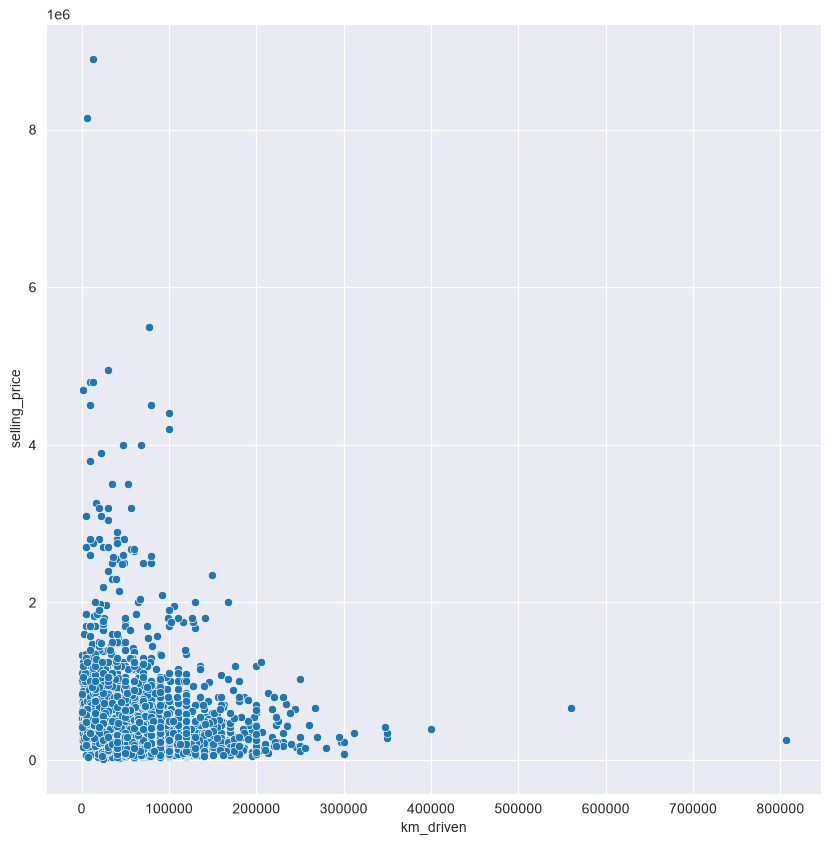

In [16]:
plt.figure(figsize=(10,10))
sns.scatterplot(data=df, x='km_driven', y='selling_price')

In [17]:
print(df[['km_driven','selling_price']].corr())

               km_driven  selling_price
km_driven       1.000000      -0.192289
selling_price  -0.192289       1.000000


<Axes: xlabel='km_driven', ylabel='selling_price'>

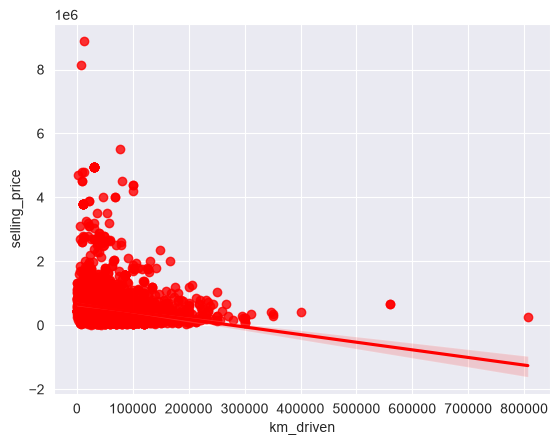

In [18]:
sns.regplot(data=df, x='km_driven', y='selling_price', color='red')

In [19]:
X=df.drop(columns='selling_price')

In [20]:
y=df[['selling_price']]

In [21]:
y

,selling_price
0,60000
1,135000
2,600000
3,250000
4,450000
...,...
4335,409999
4336,409999
4337,110000
4338,865000


In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((3472, 7), (868, 7), (3472, 1), (868, 1))

In [24]:
lr=LinearRegression()
lr.fit(X_train, y_train)

ValueError: could not convert string to float: 'Mahindra Scorpio S11 BSIV'

In [65]:
y_pred=lr.predict(X_test)
# the below error is coming because i haved transfrmed categorical data to numerical data and used those categorical features in X

ValueError: could not convert string to float: 'Tata Manza Aqua Quadrajet BS IV'

In [25]:
r2=r2_score(y_test,y_pred)

NameError: name 'y_pred' is not defined

In [26]:
print("r2 score:",r2)

NameError: name 'r2' is not defined

TypeError: unhashable type: 'numpy.ndarray'

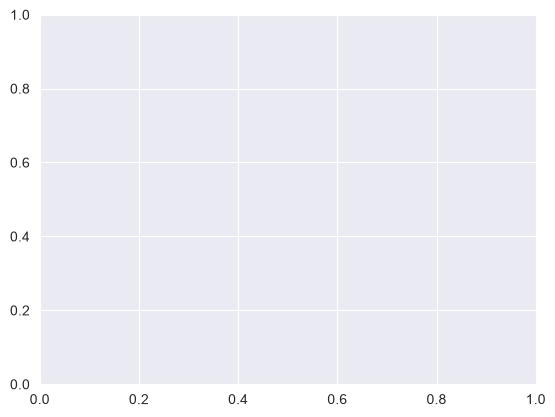

In [27]:
plt.scatter(X_test, y_test, color='black', alpha=0.5, label='Actual prices')
idx=np.argsort(X_test.values.ravel())
plt.plot(
    X_test.values.ravel()[idx],
    y_pred[idx],
    color='red',
    linewidth=2,
    label='Trained regression line'
)
plt.xlabel('kilometers driven')
plt.ylabel('price')
plt.legend()
plt.show()

In [28]:
y_test

,selling_price
3978,165000
1448,250000
2664,120000
17,450000
1634,730000
...,...
3468,130000
3164,350000
416,150000
1616,650000


In [29]:
y_pred

NameError: name 'y_pred' is not defined

In [30]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
print('mean_absolute_error:', mean_absolute_error(y_test, y_pred))
print('mean_squared_error:', mean_squared_error(y_test, y_pred))
print('r2_score:', r2_score(y_test, y_pred))

NameError: name 'y_pred' is not defined

In [31]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [32]:
# so i have these features: name, year, selling_price, km_driven, fuel, seller_type, transmission, owner

In [33]:
# df2=df[['year', 'selling_price', 'km_driven', 'fuel','seller_type', 'transmission', 'owner']]
# we will apply one hot encoding to these features: fuel , seller type, transmission, owner and covert categorical data to numerical data as machine learnig models only work with numerical data

In [34]:
df2=df.iloc[:,1:]

In [35]:
df2

,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,2014,450000,141000,Diesel,Individual,Manual,Second Owner
...,...,...,...,...,...,...,...
4335,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,2016,865000,90000,Diesel,Individual,Manual,First Owner


In [36]:
#TIME TO TRANSFORM CATEGORICAL FEATURES IN NUMERICAL FEATURES USING ONE HOT ENCODING
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
cat_cols=['fuel', 'seller_type',
          'transmission', 'owner'] #we are storing names of columns that we ll consider as categorial columns later

In [37]:
preprocessor=ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ],
    remainder='passthrough'
)

In [38]:
#fit and transform features now
X=df2.drop(columns='selling_price')
y=df2[['selling_price']]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train_transformed=preprocessor.fit_transform(X_train)
X_test_transformed=preprocessor.transform(X_test)
print(X_train_transformed)
print("xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx")
print(X_test_transformed)

[[0.000e+00 1.000e+00 0.000e+00 ... 0.000e+00 2.017e+03 2.000e+04]
 [0.000e+00 1.000e+00 0.000e+00 ... 0.000e+00 2.018e+03 5.000e+04]
 [0.000e+00 0.000e+00 0.000e+00 ... 0.000e+00 2.013e+03 2.500e+04]
 ...
 [0.000e+00 1.000e+00 0.000e+00 ... 0.000e+00 2.016e+03 5.100e+04]
 [0.000e+00 1.000e+00 0.000e+00 ... 0.000e+00 2.013e+03 8.000e+04]
 [0.000e+00 0.000e+00 0.000e+00 ... 0.000e+00 2.013e+03 8.000e+04]]
xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx
[[0.0000e+00 1.0000e+00 0.0000e+00 ... 0.0000e+00 2.0100e+03 8.0000e+04]
 [0.0000e+00 0.0000e+00 0.0000e+00 ... 0.0000e+00 2.0190e+03 2.7000e+04]
 [0.0000e+00 0.0000e+00 0.0000e+00 ... 0.0000e+00 2.0080e+03 4.1723e+04]
 ...
 [0.0000e+00 1.0000e+00 0.0000e+00 ... 0.0000e+00 2.0110e+03 4.0000e+04]
 [0.0000e+00 0.0000e+00 0.0000e+00 ... 0.0000e+00 2.0170e+03 6.4800e+03]
 [0.0000e+00 0.0000e+00 0.0000e+00 ... 0.0000e+00 2.0190e+03 3.0000e+04]]


In [39]:
#now lets tran the lr model on basis of new x train transformed and x test transformed and thn ll make predictions using the lr model and the calculate metrics and r2 score with help of y test
lr=LinearRegression()
lr.fit(X_train_transformed, y_train)
y_pred=lr.predict(X_test_transformed)
r2=r2_score(y_test,y_pred)
print("r2 score:",r2)


r2 score: 0.403324828806483


# PLOTTING THE MODEL

Actual shape: (868,)
Predicted shape: (868,)


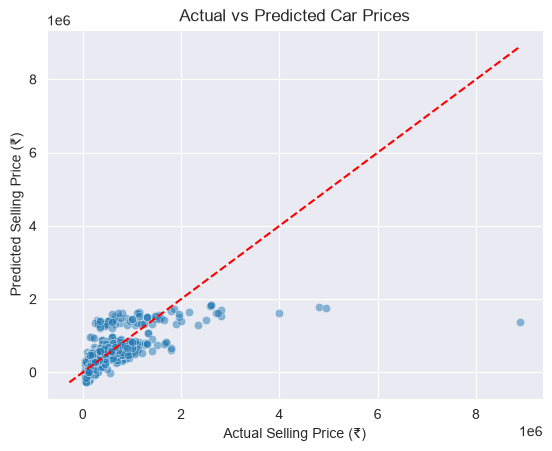

In [45]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

y_actual = np.asarray(y_test).reshape(-1)
y_pred_1d = np.asarray(y_pred).reshape(-1)

print("Actual shape:", y_actual.shape)
print("Predicted shape:", y_pred_1d.shape)

assert len(y_actual) == len(y_pred_1d), "Actual and predicted lengths differ!"

sns.scatterplot(x=y_actual, y=y_pred_1d, alpha=0.5)

low = min(y_actual.min(), y_pred_1d.min())
high = max(y_actual.max(), y_pred_1d.max())
plt.plot([low, high], [low, high], 'r--')

plt.xlabel("Actual Selling Price (₹)")
plt.ylabel("Predicted Selling Price (₹)")
plt.title("Actual vs Predicted Car Prices")
plt.show()

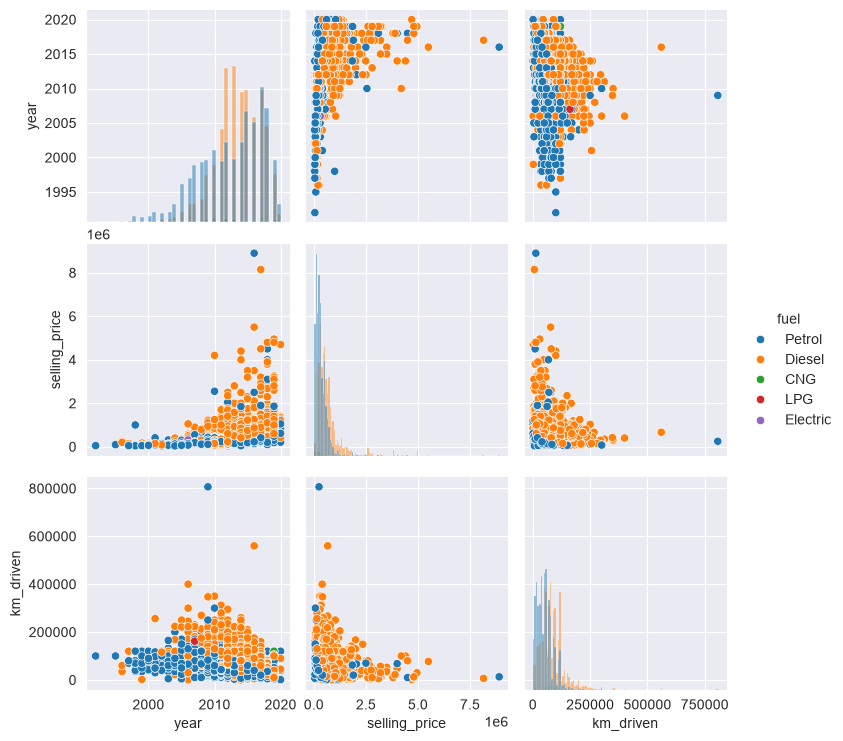

In [41]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df, hue='fuel', diag_kind='hist')
plt.show()

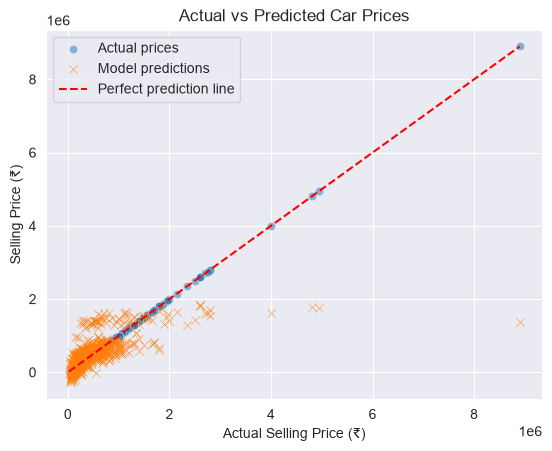

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

actual = np.asarray(y_test).ravel()
predicted = np.asarray(y_pred).ravel()

sns.scatterplot(x=actual, y=actual, marker='o', label='Actual prices', alpha=0.5)
sns.scatterplot(x=actual, y=predicted, marker='x', label='Model predictions', alpha=0.7)

plt.plot([actual.min(), actual.max()], [actual.min(), actual.max()],
         'r--', label='Perfect prediction line')

plt.xlabel('Actual Selling Price (₹)')
plt.ylabel('Selling Price (₹)')
plt.title('Actual vs Predicted Car Prices')
plt.legend()
plt.show()